# Ray Serve: gRPC ingress

A gRPC ingress node adds a gRPC proxy on port 9000 with a servicer function; the deployment answers protobuf requests.

**When to use it.** Low-latency service-to-service calls with a typed protobuf contract instead of JSON over HTTP.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

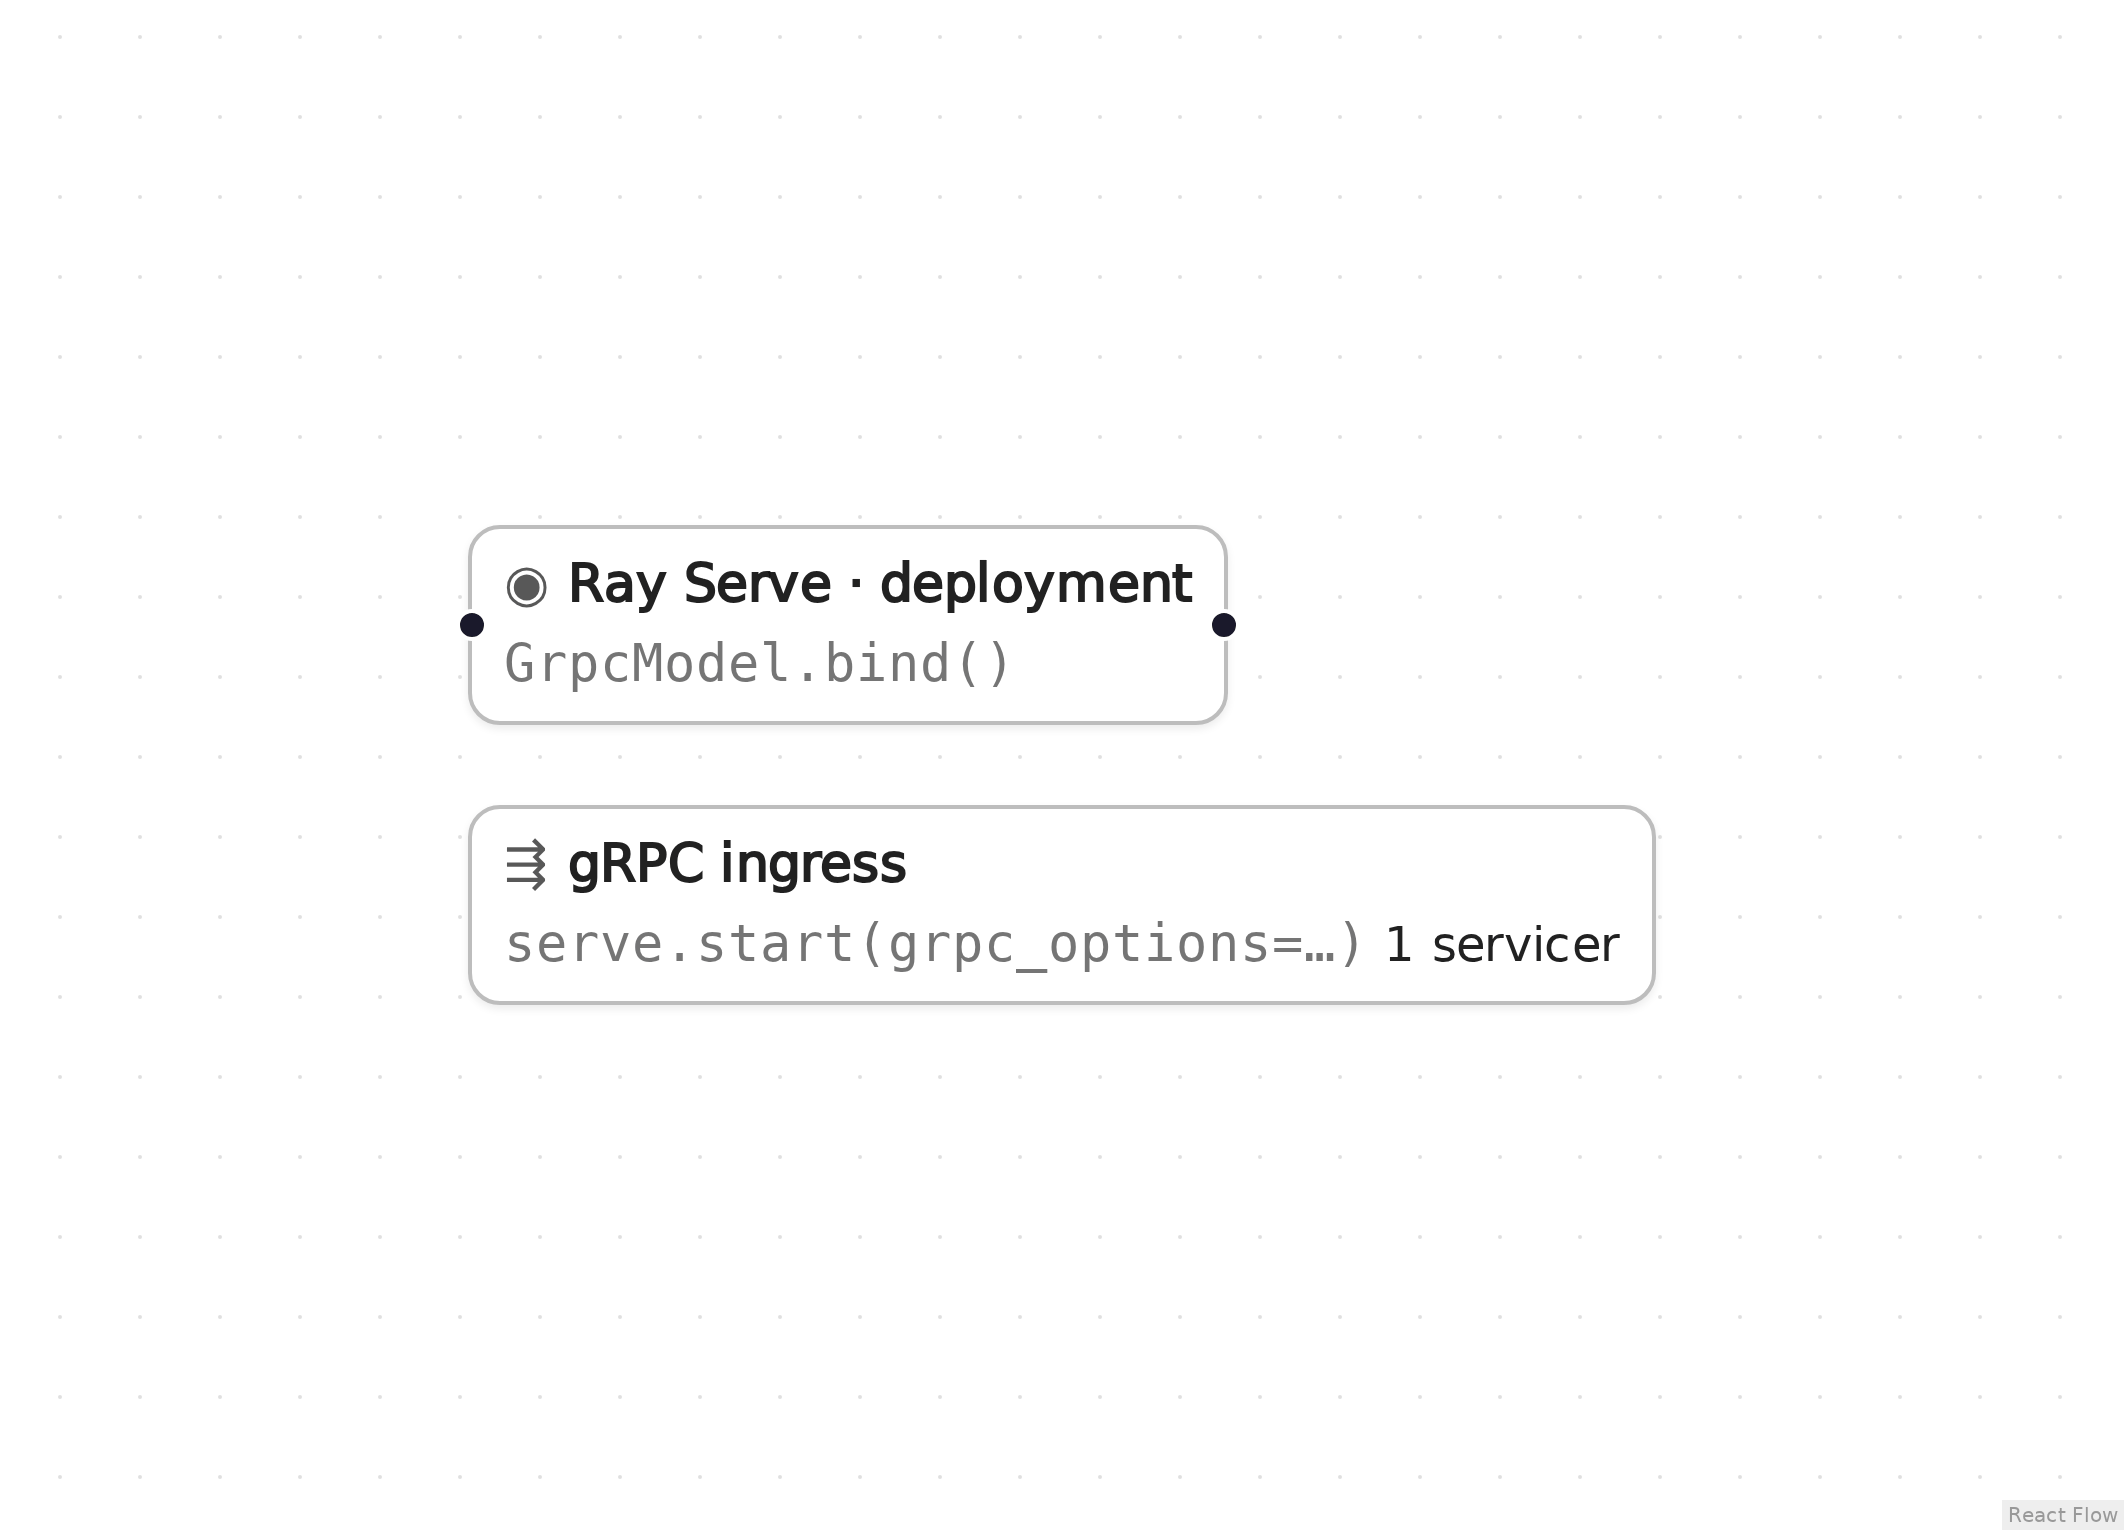

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
# Ray ships a small example protobuf service (UserDefinedService); a real app uses
# servicer functions generated from its own .proto file with grpcio-tools.
from ray import serve
from ray.serve.generated.serve_pb2 import UserDefinedResponse


@serve.deployment
class GrpcModel:
    def __call__(self, user_message):
        greeting = f"Hello {user_message.name} from {user_message.foo}"
        return UserDefinedResponse(greeting=greeting, num_x2=user_message.num * 2)

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import serve
import ray
from ray.serve.config import gRPCOptions

if not ray.is_initialized():
    ray.init()

serve.start(grpc_options=gRPCOptions(port=9000, grpc_servicer_functions=["ray.serve.generated.serve_pb2_grpc.add_UserDefinedServiceServicer_to_server"]))
_deploy_n1 = GrpcModel.bind()
serve.run(_deploy_n1)

DeploymentHandle(deployment='GrpcModel')

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
import grpc
from ray.serve.generated.serve_pb2 import UserDefinedMessage
from ray.serve.generated.serve_pb2_grpc import UserDefinedServiceStub

with grpc.insecure_channel("127.0.0.1:9000") as channel:
    stub = UserDefinedServiceStub(channel)
    reply = stub.__call__(UserDefinedMessage(name="ray", foo="the gallery", num=21), timeout=30)
assert reply.num_x2 == 42, reply
print(reply.greeting, reply.num_x2)

Hello ray from the gallery 42


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–5 and 7–8)

```python
# Generated with Eugo's visual Ray builder
...
from ray import serve
import ray
from ray.serve.config import gRPCOptions
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**gRPC ingress** (node `g1`, line 10)

```python
serve.start(grpc_options=gRPCOptions(port=9000, grpc_servicer_functions=["ray.serve.generated.serve_pb2_grpc.add_UserDefinedServiceServicer_to_server"]))
```

serve.start(grpc_options=gRPCOptions(port=9000, grpc_servicer_functions=[...])) registers the servicer; each entry is the import path of an add_..._to_server function.

**Deployment** (node `n1`, lines 11–12)

```python
_deploy_n1 = GrpcModel.bind()
serve.run(_deploy_n1)
```

The deployment's __call__ receives the decoded request message and returns a response message.

## Clean up

Shut down Serve and then Ray, so the next notebook starts fresh.

In [5]:
from ray import serve

serve.shutdown()
ray.shutdown()